# NVD CVE CVSS KEV EPSS Vulnerability Map

A practical vulnerability-priority notebook for the NVD CVE CVSS KEV EPSS 2020-2026 dataset.

It uses official NVD CVE JSON 2.0 feeds joined to the CISA Known Exploited Vulnerabilities catalog and FIRST EPSS current scores. KEV is a positive known-exploited signal, not a complete negative label for all other CVEs. EPSS is a probabilistic current risk score, not a guarantee of exploitation.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATASET_SLUG = "nvd-cve-cvss-kev-vulnerabilities-2020-2026"
candidates = [
    Path(f"/kaggle/input/{DATASET_SLUG}"),
    Path("dataset_nvd_cve_kev"),
    Path("../dataset_nvd_cve_kev"),
    Path("../../dataset_nvd_cve_kev"),
]
data_dir = next((p for p in candidates if (p / "nvd_cve_records.csv").exists()), None)
if data_dir is None and Path("/kaggle/input").exists():
    matches = list(Path("/kaggle/input").glob("**/nvd_cve_records.csv"))
    data_dir = matches[0].parent if matches else None
if data_dir is None:
    raise FileNotFoundError("NVD CVE KEV dataset not found")

usecols = [
    "cve_id", "published_year", "vuln_status", "description_length",
    "reference_count", "weakness_count", "cpe_match_count",
    "best_cvss_version", "best_cvss_base_score", "best_cvss_base_severity",
    "cvss_v31_attack_vector", "cvss_v31_attack_complexity",
    "cvss_v31_privileges_required", "cvss_v31_user_interaction", "cvss_v31_scope",
    "primary_cwe_id", "mentions_rce", "mentions_sql_injection",
    "mentions_xss", "mentions_exploit_public", "mentions_buffer_overflow",
    "kev_is_known_exploited", "epss_score", "epss_percentile",
    "epss_risk_bucket", "epss_top_1_percent", "epss_top_5_percent",
]
available = pd.read_csv(data_dir / "nvd_cve_records.csv", nrows=0).columns.tolist()
records = pd.read_csv(data_dir / "nvd_cve_records.csv", usecols=[c for c in usecols if c in available], low_memory=False)
if "epss_score" not in records.columns and (data_dir / "first_epss_current.csv").exists():
    epss = pd.read_csv(data_dir / "first_epss_current.csv", usecols=["cve_id", "epss_score", "epss_percentile"], low_memory=False)
    records = records.merge(epss, on="cve_id", how="left")
if "epss_score" not in records.columns:
    records["epss_score"] = np.nan
if "epss_percentile" not in records.columns:
    records["epss_percentile"] = np.nan
if "epss_risk_bucket" not in records.columns:
    records["epss_risk_bucket"] = pd.cut(
        records["epss_score"].fillna(-1),
        bins=[-1, 0.01, 0.1, 0.5, 1.0],
        labels=["low", "medium", "high", "very_high"],
        include_lowest=True,
    ).astype("object")
    records.loc[records["epss_score"].isna(), "epss_risk_bucket"] = np.nan
if "epss_top_1_percent" not in records.columns:
    records["epss_top_1_percent"] = records["epss_percentile"] >= 0.99
if "epss_top_5_percent" not in records.columns:
    records["epss_top_5_percent"] = records["epss_percentile"] >= 0.95
yearly = pd.read_csv(data_dir / "yearly_summary.csv")
severity = pd.read_csv(data_dir / "severity_summary.csv")
cwe = pd.read_csv(data_dir / "cwe_summary.csv")
vendor = pd.read_csv(data_dir / "vendor_product_summary.csv")
if (data_dir / "epss_summary.csv").exists():
    epss_summary = pd.read_csv(data_dir / "epss_summary.csv")
else:
    epss_summary = (
        records.groupby("epss_risk_bucket", dropna=False)
        .agg(
            cves=("cve_id", "nunique"),
            kev_known_exploited=("kev_is_known_exploited", "sum"),
            median_cvss=("best_cvss_base_score", "median"),
            median_epss=("epss_score", "median"),
            max_epss=("epss_score", "max"),
        )
        .reset_index()
    )
print("records", records.shape)
print("known exploited in KEV", int(records["kev_is_known_exploited"].sum()))
print("with EPSS", int(records["epss_score"].notna().sum()))
print("year range", int(records["published_year"].min()), int(records["published_year"].max()))
records.head()

records (201542, 27)
known exploited in KEV 1039
with EPSS 194478
year range 2020 2026


,cve_id,vuln_status,description_length,reference_count,weakness_count,cpe_match_count,cvss_v31_attack_vector,cvss_v31_attack_complexity,cvss_v31_privileges_required,cvss_v31_user_interaction,...,mentions_xss,mentions_exploit_public,mentions_buffer_overflow,kev_is_known_exploited,epss_score,epss_percentile,epss_risk_bucket,epss_top_1_percent,epss_top_5_percent,published_year
0,CVE-2026-7228,Received,330,5,2,0,NETWORK,LOW,NONE,NONE,...,False,False,False,False,0.0003,0.08526,low,False,False,2026
1,CVE-2026-7227,Received,295,5,2,0,NETWORK,LOW,NONE,NONE,...,False,False,False,False,0.0003,0.08526,low,False,False,2026
2,CVE-2026-7226,Received,340,5,2,0,NETWORK,LOW,NONE,NONE,...,False,False,False,False,0.0003,0.08526,low,False,False,2026
3,CVE-2026-7225,Received,367,5,2,0,NETWORK,LOW,NONE,NONE,...,False,False,False,False,0.0003,0.08526,low,False,False,2026
4,CVE-2026-7224,Received,351,5,2,0,NETWORK,LOW,NONE,NONE,...,False,True,False,False,0.0003,0.08526,low,False,False,2026


,published_year,cves,kev_known_exploited,median_cvss,mean_cvss,critical_count,high_count,cves_with_cpe,cves_with_cwe,cves_with_epss,median_epss,epss_top_1_percent
0,2020,14377,136,7.5,7.110979,2008,6055,14263,14243,14263,0.003730,255
1,2021,21019,213,7.5,7.084002,2598,8415,19821,19799,19821,0.003160,294
2,2022,25793,128,7.5,7.189645,4176,10021,24714,24596,24714,0.002975,260
3,2023,29377,162,7.3,7.100078,4360,10850,28282,27630,28282,0.001730,351
4,2024,40484,159,6.5,6.801546,4251,13942,32017,39613,39753,0.001780,382
5,2025,49549,193,6.5,6.629709,4005,15334,30040,46294,47821,0.000870,77
6,2026,20943,48,6.9,6.799533,2025,7448,12018,19298,19824,0.000380,9


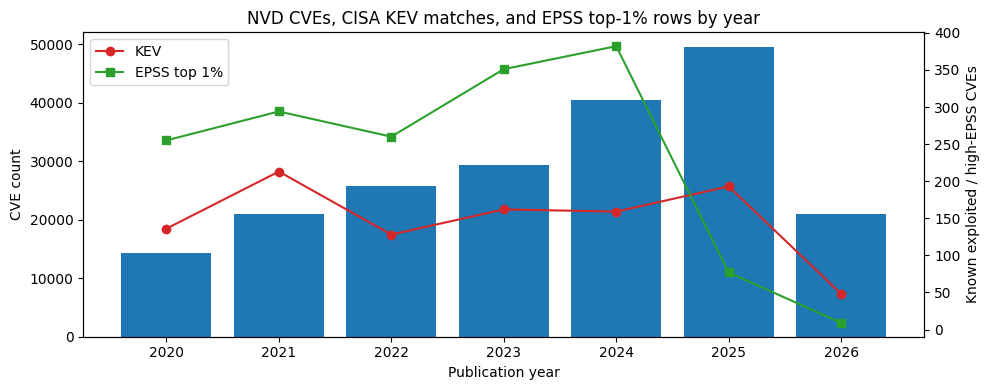

In [2]:
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(yearly["published_year"], yearly["cves"], color="tab:blue", label="CVEs")
ax1.set_ylabel("CVE count")
ax1.set_xlabel("Publication year")
ax1.set_title("NVD CVEs, CISA KEV matches, and EPSS top-1% rows by year")
ax2 = ax1.twinx()
ax2.plot(yearly["published_year"], yearly["kev_known_exploited"], color="tab:red", marker="o", label="KEV")
ax2.plot(yearly["published_year"], yearly["epss_top_1_percent"], color="tab:green", marker="s", label="EPSS top 1%")
ax2.set_ylabel("Known exploited / high-EPSS CVEs")
ax2.legend(loc="upper left")
fig.tight_layout()
yearly

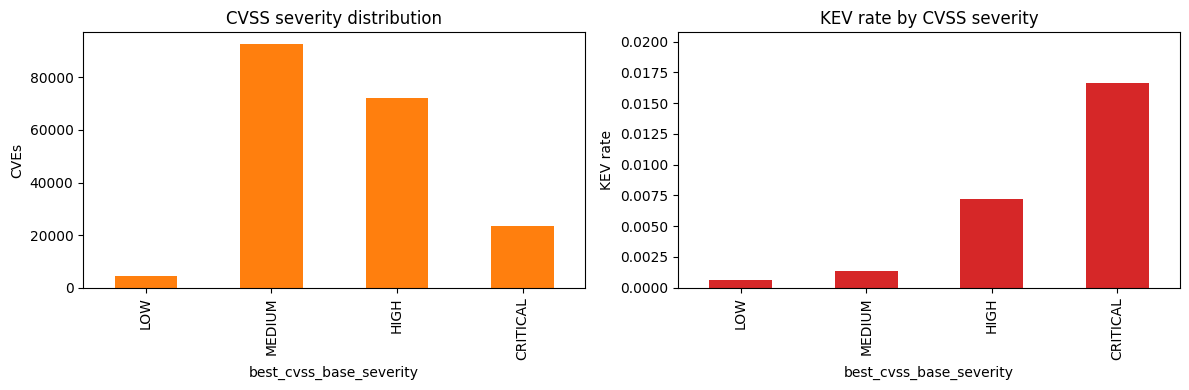

In [3]:
sev_order = ["LOW", "MEDIUM", "HIGH", "CRITICAL"]
sev_counts = records["best_cvss_base_severity"].value_counts().reindex(sev_order)
kev_rate = records.groupby("best_cvss_base_severity")["kev_is_known_exploited"].mean().reindex(sev_order)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sev_counts.plot(kind="bar", ax=axes[0], color="tab:orange", title="CVSS severity distribution")
axes[0].set_ylabel("CVEs")
kev_rate.plot(kind="bar", ax=axes[1], color="tab:red", title="KEV rate by CVSS severity")
axes[1].set_ylabel("KEV rate")
axes[1].set_ylim(0, max(0.01, float(kev_rate.max()) * 1.25))
plt.tight_layout()

,epss_risk_bucket,cves,kev_known_exploited,median_cvss,median_epss,max_epss
0,very_high,2751,530,8.8,0.82461,0.94520
1,high,4499,179,8.4,0.19668,0.49873
2,medium,18147,190,7.8,0.02079,0.09998
3,low,169081,140,6.5,0.00127,0.00999
4,NaN,7064,0,5.3,NaN,NaN


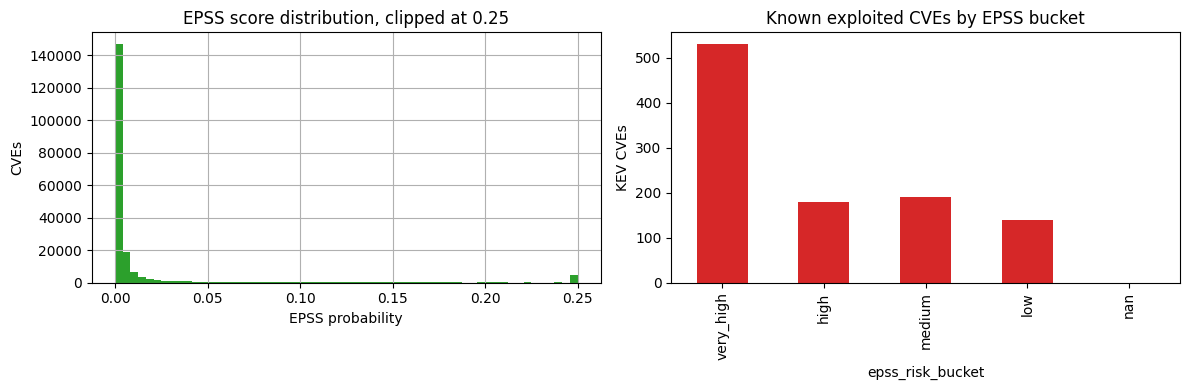

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
records["epss_score"].dropna().clip(upper=0.25).hist(bins=60, ax=axes[0], color="tab:green")
axes[0].set_title("EPSS score distribution, clipped at 0.25")
axes[0].set_xlabel("EPSS probability")
axes[0].set_ylabel("CVEs")
epss_summary.set_index("epss_risk_bucket")["kev_known_exploited"].plot(kind="bar", ax=axes[1], color="tab:red")
axes[1].set_title("Known exploited CVEs by EPSS bucket")
axes[1].set_ylabel("KEV CVEs")
plt.tight_layout()
epss_summary

In [5]:
priority_cols = [
    "cve_id", "published_year", "best_cvss_base_score", "best_cvss_base_severity",
    "epss_score", "epss_percentile", "epss_risk_bucket",
    "kev_is_known_exploited", "primary_cwe_id", "reference_count", "cpe_match_count",
]
records.sort_values(["kev_is_known_exploited", "epss_score", "best_cvss_base_score"], ascending=[False, False, False])[priority_cols].head(25)

,cve_id,published_year,best_cvss_base_score,best_cvss_base_severity,epss_score,epss_percentile,epss_risk_bucket,kev_is_known_exploited,primary_cwe_id,reference_count,cpe_match_count
136773,CVE-2023-23752,2023,5.3,MEDIUM,0.94520,1.00000,very_high,True,NVD-CWE-Other,3,1
182412,CVE-2021-22986,2021,9.8,CRITICAL,0.94485,0.99999,very_high,True,CWE-918,7,73
200294,CVE-2020-1938,2020,9.8,CRITICAL,0.94469,0.99998,very_high,True,NVD-CWE-Other,103,38
84099,CVE-2024-6670,2024,9.8,CRITICAL,0.94468,0.99997,very_high,True,CWE-89,3,1
142727,CVE-2022-46169,2022,9.8,CRITICAL,0.94468,0.99997,very_high,True,CWE-74,9,1
180875,CVE-2021-22205,2021,10.0,CRITICAL,0.94467,0.99997,very_high,True,CWE-94,11,6
108840,CVE-2024-23897,2024,9.8,CRITICAL,0.94466,0.99996,very_high,True,CWE-22,12,2
159776,CVE-2022-22963,2022,9.8,CRITICAL,0.94462,0.99995,very_high,True,CWE-94,13,47
161760,CVE-2022-22947,2022,10.0,CRITICAL,0.94461,0.99995,very_high,True,CWE-94,11,16
167906,CVE-2021-44529,2021,9.8,CRITICAL,0.94461,0.99995,very_high,True,CWE-94,7,2


In [6]:
display_cols = ["cwe_id", "cves", "kev_known_exploited", "median_cvss", "median_epss", "epss_top_1_percent"]
cwe[display_cols].head(25)

,cwe_id,cves,kev_known_exploited,median_cvss,median_epss,epss_top_1_percent
0,CWE-79,30125,38,5.4,0.00197,72
1,NVD-CWE-noinfo,21435,143,6.8,0.00234,165
2,CWE-89,12531,36,7.5,0.00196,204
3,CWE-787,10457,163,7.8,0.00237,60
4,CWE-862,7295,13,5.4,0.00119,41
5,CWE-352,6395,4,6.8,0.00106,6
6,CWE-125,5760,21,7.1,0.00122,5
7,CWE-22,5295,100,7.5,0.00420,255
8,CWE-416,5023,121,7.8,0.00117,16
9,CWE-20,4629,41,7.5,0.00190,39


,cpe_vendor,cpe_product,cves,kev_known_exploited,median_cvss,median_epss,max_epss,epss_top_1_percent
0,linux,linux kernel,11919,114,5.5,0.000180,0.94444,24
1,google,android,5249,42,6.7,0.000190,0.67932,0
2,apple,macos,4825,123,7.1,0.001200,0.92544,15
3,microsoft,windows,4793,50,7.8,0.001770,0.94374,18
4,debian,debian linux,4639,137,7.1,0.003140,0.94469,132
5,microsoft,windows server 2019,3950,144,7.8,0.006430,0.94400,52
6,fedoraproject,fedora,3779,164,7.5,0.004015,0.94469,161
7,microsoft,windows server 2016,3710,141,7.8,0.006050,0.94400,65
8,microsoft,windows server 2012,2754,225,7.8,0.009490,0.94380,92
9,microsoft,windows server 2022,2691,105,7.8,0.006530,0.94400,32


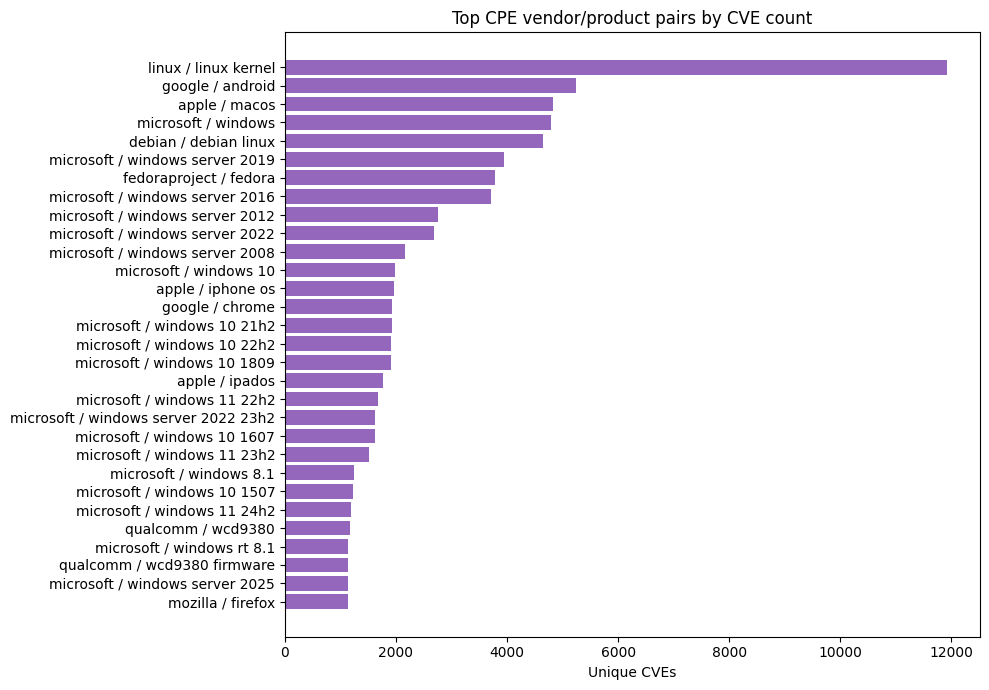

In [7]:
top_vendor = vendor.dropna(subset=["cpe_vendor", "cpe_product"]).head(30)
fig, ax = plt.subplots(figsize=(10, 7))
labels = (top_vendor["cpe_vendor"].astype(str) + " / " + top_vendor["cpe_product"].astype(str)).str[:48]
ax.barh(labels[::-1], top_vendor["cves"].values[::-1], color="tab:purple")
ax.set_title("Top CPE vendor/product pairs by CVE count")
ax.set_xlabel("Unique CVEs")
plt.tight_layout()
top_vendor[["cpe_vendor", "cpe_product", "cves", "kev_known_exploited", "median_cvss", "median_epss", "max_epss", "epss_top_1_percent"]]

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

model_df = records.dropna(subset=["best_cvss_base_score", "published_year"]).copy()
y = model_df["kev_is_known_exploited"].astype(int)
features = [
    "published_year", "description_length", "reference_count", "weakness_count", "cpe_match_count",
    "best_cvss_base_score", "best_cvss_base_severity", "epss_score", "epss_percentile",
    "epss_risk_bucket", "epss_top_1_percent", "epss_top_5_percent", "cvss_v31_attack_vector",
    "cvss_v31_attack_complexity", "cvss_v31_privileges_required",
    "cvss_v31_user_interaction", "cvss_v31_scope", "primary_cwe_id",
    "mentions_rce", "mentions_sql_injection", "mentions_xss",
    "mentions_exploit_public", "mentions_buffer_overflow",
]
X = model_df[features]
categorical = X.select_dtypes(include=["object"]).columns.tolist()
numeric = [c for c in X.columns if c not in categorical]

try:
    encoder = OneHotEncoder(handle_unknown="ignore", min_frequency=25)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore")

preprocess = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeric),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", encoder)]), categorical),
])
clf = Pipeline([
    ("preprocess", preprocess),
    ("model", LogisticRegression(max_iter=300, class_weight="balanced", n_jobs=1)),
])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
clf.fit(X_train, y_train)
proba = clf.predict_proba(X_test)[:, 1]
print("ROC AUC:", round(roc_auc_score(y_test, proba), 4))
print("Average precision:", round(average_precision_score(y_test, proba), 4))
print(classification_report(y_test, proba >= np.quantile(proba, 0.98), digits=3))

ROC AUC: 0.9893
Average precision: 0.4094
              precision    recall  f1-score   support

           0      0.999     0.984     0.991     47882
           1      0.212     0.785     0.334       260

    accuracy                          0.983     48142
   macro avg      0.605     0.884     0.663     48142
weighted avg      0.995     0.983     0.988     48142



## Modeling caveat

The baseline treats CISA KEV membership as the positive class. Non-KEV rows are not guaranteed unexploited; they are simply not in the KEV catalog at the dataset build time. EPSS is a current probabilistic signal and changes over time. Use the model as a screening demo, not as an operational exploitability oracle.